# Modul 3 — Regresi: Apa yang menggerakkan Energi per Ton dan Recovery?
Kita menulis OLS **dari nol dengan numpy** supaya paham tiap angka pada keluaran regresi, lalu (opsional, di Colab) mencocokkannya dengan `statsmodels`.

Alur: model → koefisien & p-value → diagnostik asumsi (VIF, heteroskedastisitas, autokorelasi, normalitas residu) → galat robust (HC3) → validasi silang.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
h, pr = S["Data_Harian"], S["Proses_Harian"]
for df in (h, pr): df["Tanggal"] = pd.to_datetime(df["Tanggal"])
df = h.merge(pr, on="Tanggal").sort_values("Tanggal").reset_index(drop=True)

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


## 1. Fungsi OLS buatan sendiri
Rumus inti: **β = (XᵀX)⁻¹ Xᵀy**. Galat baku koefisien = akar diagonal dari σ²(XᵀX)⁻¹. Statistik t = β/SE, p dari sebaran t.

In [ ]:
def ols(X, y, nama):
    """X: DataFrame prediktor (tanpa konstanta). Mengembalikan dict hasil lengkap."""
    Xm = np.column_stack([np.ones(len(X)), X.values.astype(float)]); yv = y.values.astype(float)
    n, k = Xm.shape
    XtX_inv = np.linalg.inv(Xm.T @ Xm)
    beta = XtX_inv @ Xm.T @ yv
    res = yv - Xm @ beta
    sse = res @ res; sst = ((yv - yv.mean()) ** 2).sum()
    s2 = sse / (n - k)
    se = np.sqrt(np.diag(s2 * XtX_inv))
    # galat robust HC3: tahan terhadap varians residu tidak konstan
    hat = np.einsum("ij,jk,ik->i", Xm, XtX_inv, Xm)
    meat = Xm.T @ (Xm * (res**2 / (1 - hat) ** 2)[:, None])
    se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    t = beta / se; p = 2 * stats.t.sf(abs(t), n - k)
    p_hc3 = 2 * stats.t.sf(abs(beta / se_hc3), n - k)
    r2 = 1 - sse / sst; adj = 1 - (1 - r2) * (n - 1) / (n - k)
    F = ((sst - sse) / (k - 1)) / s2; pF = stats.f.sf(F, k - 1, n - k)
    aic = n * np.log(sse / n) + 2 * k
    tabel = pd.DataFrame({"koef": beta, "SE": se, "t": t, "p": p, "SE_HC3": se_hc3, "p_HC3": p_hc3},
                         index=["const"] + list(X.columns))
    return dict(nama=nama, tabel=tabel, res=res, fitted=yv - res, Xm=Xm, y=yv, n=n, k=k, r2=r2, adj=adj, F=F, pF=pF, aic=aic, s2=s2)

def ringkas(m):
    print(f"\n=== {m['nama']} ===  n={m['n']}  R²={m['r2']:.3f}  R² adj={m['adj']:.3f}  F={m['F']:.1f} (p={m['pF']:.2g})  AIC={m['aic']:.1f}")
    print(m["tabel"].round(4).to_string())

def diagnostik(m, X):
    n, k = m["n"], m["k"]; res = m["res"]
    # VIF: seberapa besar variansi koefisien membengkak karena prediktor saling berkorelasi
    vif = {}
    for j, c in enumerate(X.columns):
        others = np.column_stack([np.ones(n), np.delete(X.values.astype(float), j, axis=1)])
        bj = np.linalg.lstsq(others, X[c].values.astype(float), rcond=None)[0]
        r2j = 1 - ((X[c].values - others @ bj) ** 2).sum() / ((X[c].values - X[c].values.mean()) ** 2).sum()
        vif[c] = 1 / (1 - r2j)
    print("VIF (>5 waspada, >10 bermasalah):", {c: round(float(v), 2) for c, v in vif.items()})
    # Breusch-Pagan: regresikan residu^2 pada prediktor; LM = n * R²
    e2 = res ** 2; bb = np.linalg.lstsq(m["Xm"], e2, rcond=None)[0]
    r2bp = 1 - ((e2 - m["Xm"] @ bb) ** 2).sum() / ((e2 - e2.mean()) ** 2).sum()
    lm = n * r2bp; print(f"Breusch-Pagan: LM={lm:.2f}, p={stats.chi2.sf(lm, k-1):.3f}  (p<0.05 = varians residu tidak konstan)")
    dw = (np.diff(res) ** 2).sum() / (res ** 2).sum(); print(f"Durbin-Watson={dw:.2f}  (≈2 tidak ada autokorelasi; <1.5 positif)")
    jb = stats.jarque_bera(res); print(f"Jarque-Bera: p={jb.pvalue:.3f}  skew={stats.skew(res):.2f}  kurtosis berlebih={stats.kurtosis(res):.2f}")
    return vif

## 2. Model 1 — Energi per ton katoda
Prediktor kandidat dari proses: suhu FSF, pengayaan O₂, kelembaban konsentrat, jam downtime, kadar Cu konsentrat.

In [ ]:
pred1 = ["Suhu_FSF_C", "O2_Enrichment_Persen", "Kelembaban_Konsentrat_Persen", "Jam_Downtime", "Cu_Grade_Persen"]
X1, y1 = df[pred1], df["Energi_per_t_Katoda_MWh"]
m1 = ols(X1, y1, "Energi per ton ~ proses"); ringkas(m1); vif1 = diagnostik(m1, X1)


=== Energi per ton ~ proses ===  n=273  R²=0.770  R² adj=0.766  F=179.1 (p=4e-83)  AIC=-1867.2
                                koef      SE        t       p  SE_HC3   p_HC3
const                        -0.5294  0.2816  -1.8797  0.0612  0.2814  0.0610
Suhu_FSF_C                    0.0024  0.0002  13.1515  0.0000  0.0002  0.0000
O2_Enrichment_Persen         -0.0163  0.0015 -10.9135  0.0000  0.0014  0.0000
Kelembaban_Konsentrat_Persen  0.0006  0.0029   0.2058  0.8371  0.0029  0.8356
Jam_Downtime                  0.0064  0.0008   8.3381  0.0000  0.0008  0.0000
Cu_Grade_Persen               0.0000  0.0022   0.0071  0.9943  0.0022  0.9943
VIF (>5 waspada, >10 bermasalah): {'Suhu_FSF_C': 1.46, 'O2_Enrichment_Persen': 1.33, 'Kelembaban_Konsentrat_Persen': 1.0, 'Jam_Downtime': 1.26, 'Cu_Grade_Persen': 1.0}
Breusch-Pagan: LM=4.28, p=0.510  (p<0.05 = varians residu tidak konstan)
Durbin-Watson=2.13  (≈2 tidak ada autokorelasi; <1.5 positif)
Jarque-Bera: p=0.660  skew=-0.08  kurtosis berlebih=-0.

**Membaca tabel:** `koef` = perubahan energi/t per kenaikan 1 satuan prediktor dengan yang lain tetap. `p_HC3` memakai galat robust; jika `p` dan `p_HC3` berbeda jauh, curigai heteroskedastisitas.

### Koefisien terstandar — prediktor mana yang paling berpengaruh?
Koefisien mentah tidak sebanding karena satuannya beda. Setelah dibakukan (z-score), besar koefisien bisa dibandingkan.

Suhu_FSF_C                      0.466
O2_Enrichment_Persen           -0.370
Jam_Downtime                    0.274
Kelembaban_Konsentrat_Persen    0.006
Cu_Grade_Persen                 0.000
Name: koef, dtype: float64


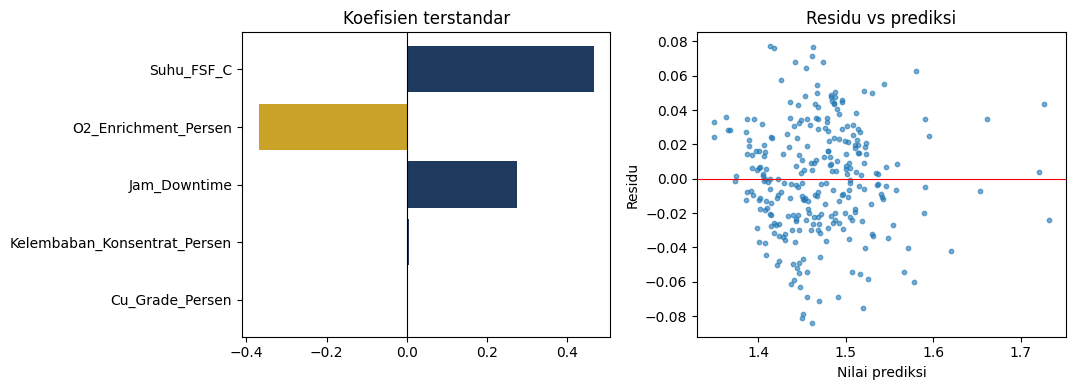

In [ ]:
z = lambda d: (d - d.mean()) / d.std()
ms = ols(z(X1), z(y1), "terstandar")
std = ms["tabel"].koef.drop("const").sort_values(key=abs, ascending=False)
print(std.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(std.index[::-1], std.values[::-1], color=["#1F3A5F" if v > 0 else "#C9A227" for v in std.values[::-1]])
ax[0].set_title("Koefisien terstandar"); ax[0].axvline(0, color="k", lw=.8)
ax[1].scatter(m1["fitted"], m1["res"], s=10, alpha=.6); ax[1].axhline(0, color="r", lw=.8)
ax[1].set_xlabel("Nilai prediksi"); ax[1].set_ylabel("Residu"); ax[1].set_title("Residu vs prediksi")
plt.tight_layout(); plt.show()

## 3. Validasi silang (apakah model tidak sekadar menghafal?)
K-fold CV 5 lipatan: latih di 4 bagian, uji di 1 bagian, ulangi. R² *out-of-sample* menjadi ukuran kejujuran model.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
cv = KFold(5, shuffle=True, random_state=0)
skor = cross_val_score(LinearRegression(), X1, y1, cv=cv, scoring="r2")
rmse = -cross_val_score(LinearRegression(), X1, y1, cv=cv, scoring="neg_root_mean_squared_error")
print("R² per lipatan:", skor.round(3), "| rata-rata", skor.mean().round(3), "| R² dalam sampel", round(m1["r2"], 3))
print(f"RMSE CV rata-rata={rmse.mean():.4f} MWh/t  (≈{rmse.mean()/y1.mean()*100:.1f}% dari rata-rata energi/t)")

R² per lipatan: [0.764 0.826 0.758 0.726 0.663] | rata-rata 0.747 | R² dalam sampel 0.77
RMSE CV rata-rata=0.0327 MWh/t  (≈2.2% dari rata-rata energi/t)


## 4. Model 2 — Recovery
Recovery diturunkan dari kehilangan Cu ke slag, sehingga `Cu_Slag_Persen` pasti berhubungan kuat. Itu **bukan temuan baru** (hampir identitas fisik) — maka kita juga lihat model tanpanya.

In [ ]:
pred2 = ["Cu_Slag_Persen", "Suhu_FSF_C", "Matte_Grade_Persen", "Jam_Downtime"]
m2 = ols(df[pred2], df["Recovery_Persen"], "Recovery ~ proses (dengan Cu slag)"); ringkas(m2)
m3 = ols(df[pred2[1:]], df["Recovery_Persen"], "Recovery ~ proses (tanpa Cu slag)"); ringkas(m3)
print("\nPelajaran: R² turun tajam tanpa Cu_Slag -> sebagian besar variasi recovery adalah 'kebocoran ke slag', bukan variabel kontrol lain.")


=== Recovery ~ proses (dengan Cu slag) ===  n=273  R²=0.888  R² adj=0.887  F=532.9 (p=3.2e-126)  AIC=-546.8
                        koef      SE        t       p  SE_HC3   p_HC3
const               106.2133  2.5706  41.3180  0.0000  2.5529  0.0000
Cu_Slag_Persen       -8.7507  0.1899 -46.0816  0.0000  0.4902  0.0000
Suhu_FSF_C           -0.0016  0.0019  -0.8661  0.3872  0.0017  0.3508
Matte_Grade_Persen    0.0123  0.0166   0.7375  0.4615  0.0149  0.4124
Jam_Downtime          0.0064  0.0085   0.7559  0.4504  0.0085  0.4510

=== Recovery ~ proses (tanpa Cu slag) ===  n=273  R²=0.003  R² adj=-0.008  F=0.3 (p=0.82)  AIC=48.7
                        koef      SE        t       p  SE_HC3   p_HC3
const               100.7718  7.6567  13.1613  0.0000  9.5749  0.0000
Suhu_FSF_C           -0.0037  0.0056  -0.6578  0.5112  0.0064  0.5689
Matte_Grade_Persen    0.0312  0.0496   0.6285  0.5302  0.0343  0.3637
Jam_Downtime          0.0134  0.0253   0.5322  0.5950  0.0206  0.5151

Pelajaran: R² turun

## 5. Regresi logistik: peluang batch Off-grade
Y = 1 jika Off-grade. Prediktor: Pb, S, Fe ppm, dan kadar Cu katoda dari lab.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score
qc = S["QC_Lab"]; Xq = qc[["Cu_Persen", "Pb_ppm", "S_ppm", "Fe_ppm"]]; yq = (qc.Status_Mutu == "Off-grade").astype(int)
print("Off-grade:", yq.sum(), "dari", len(yq))
print(qc.groupby("Status_Mutu")[["Cu_Persen", "Pb_ppm", "S_ppm", "Fe_ppm"]].mean().round(2))
Xz = StandardScaler().fit_transform(Xq)
lr = LogisticRegression(max_iter=1000, class_weight="balanced")
pp = cross_val_predict(lr, Xz, yq, cv=KFold(5, shuffle=True, random_state=1), method="predict_proba")[:, 1]
print(f"AUC (validasi silang) = {roc_auc_score(yq, pp):.3f}   (0.5 = tebakan, 1 = sempurna)")
lr.fit(Xz, yq); print(pd.Series(lr.coef_[0], index=Xq.columns).round(2).rename("koef logit terstandar"))

Off-grade: 15 dari 273
             Cu_Persen  Pb_ppm  S_ppm  Fe_ppm
Status_Mutu                                  
Grade A         100.00    1.71   4.91    2.26
Off-grade        99.99    3.97   9.22    1.99
AUC (validasi silang) = 0.957   (0.5 = tebakan, 1 = sempurna)
Cu_Persen   -2.45
Pb_ppm       2.33
S_ppm        1.97
Fe_ppm      -0.43
Name: koef logit terstandar, dtype: float64


## 6. Cocokkan dengan statsmodels (opsional, hanya di Colab)

In [ ]:
try:
    import statsmodels.api as sm
    r = sm.OLS(y1, sm.add_constant(X1)).fit()
    print("Koefisien sama dengan OLS buatan sendiri:", np.allclose(r.params.values, m1["tabel"].koef.values))
    print("R² sama:", np.isclose(r.rsquared, m1["r2"]))
    rr = sm.OLS(y1, sm.add_constant(X1)).fit(cov_type="HC3")
    print("SE HC3 sama:", np.allclose(rr.bse.values, m1["tabel"].SE_HC3.values, rtol=1e-6))
except ImportError:
    print("statsmodels tidak terpasang di lingkungan ini; lewati.")

Koefisien sama dengan OLS buatan sendiri: True
R² sama: True
SE HC3 sama: True


**Kesimpulan modul 3.**
*   Energi per ton dijelaskan oleh suhu FSF, O2 enrichment, dan jam downtime (R² 0,77; CV 0,75; RMSE sekitar 2,2% dari rata-rata). Kelembapan dan kadar Cu tidak berpengaruh. Uji diagnostik (VIF, Breusch-Pagan, Durbin-Watson, Jarque-Bera) semuanya baik.
*   Recovery: R² 0,89 dengan Cu slag, tetapi hanya 0,003 tanpa Cu slag. Variasi recovery hampir seluruhnya adalah kebocoran tembaga ke slag.
*   Dua hasil ini perlu dibaca hati-hati. Cu slag secara definisi saling terkait dengan recovery, dan AUC off-grade 0,957 memakai unsur lab yang kemungkinan ikut menentukan status mutu. Keduanya bukan temuan prediktif yang berdiri sendiri.



